# Figure 2: modeled TCN responses under fixed and fluctuating selection

In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb
plt.rcParams.update(PLOT_STYLE)

# Plotting settings faithfully matched to the supplied Figure2.pdf.
# The numerical model, parameter values, simulation and source-data exports
# are unchanged.  These colors are deliberately local to Figure 2 plotting.
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"],
    "font.size": 12,
    "axes.labelsize": 13.5,
    "axes.titlesize": 13.5,
    "axes.titleweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "axes.linewidth": 1.1,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.major.width": 1.1,
    "xtick.major.size": 4,
    "ytick.major.width": 1.1,
    "ytick.major.size": 4,
    "lines.solid_capstyle": "round",
    "savefig.dpi": 360,
    "figure.facecolor": "white",
})
REFERENCE_GREEN = "#3F9347"
REFERENCE_PALE_GREEN = "#D9ECDD"
REFERENCE_GRAY = "#D3D3D3"
REFERENCE_SHADE = "#E6F4E5"
REFERENCE_COLORS = dict(zip(CONDITION_ORDER, (
    "#C5C4DD", "#9D9BC7", "#644F9C",
)))
REFERENCE_LABELS = {
    "transposition off": "baseline",
    "transposition on": "+ transposition",
    "transposition on + PCN dynamics": "+ transposition,\n+ PCN dynamics",
}

def reference_legend_handles(kind="line"):
    if kind == "line":
        return [Line2D([], [], color=REFERENCE_COLORS[c], lw=2.25,
                       solid_capstyle="round", label=REFERENCE_LABELS[c])
                for c in CONDITION_ORDER]
    return [Line2D([], [], color=REFERENCE_COLORS[c], linestyle="None",
                   marker="o", markersize=8, label=REFERENCE_LABELS[c])
            for c in CONDITION_ORDER]

def daily_endpoints(frame, x_column):
    # The published plots join one point per *daily transfer*, rather than
    # showing hourly solver output. This only changes plotting resolution.
    daily = frame[np.isclose(frame[x_column], np.rint(frame[x_column]), atol=1e-9)]
    return daily.drop_duplicates(subset=[x_column], keep="last")

MAX_PCN = 100
CONFIGS = standard_configurations(MAX_PCN)
OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs("Figure2_outputs")

## Figure 2d: imposed TCN-growth relationships


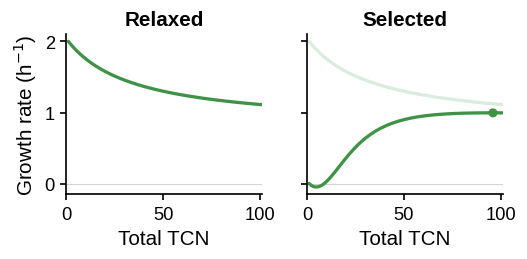

In [2]:
tcn = total_tcn_states(MAX_PCN)
relaxed_growth = growth_rates(MAX_PCN, selected=False)
selected_growth = growth_rates(MAX_PCN, selected=True)

# Published Figure 2d: two separate growth landscapes, no legend.
fig = plt.figure(figsize=(5.15, 2.60))
axes = [fig.add_axes([0.14, 0.255, 0.345, 0.56]),
        fig.add_axes([0.565, 0.255, 0.345, 0.56])]
for ax, title in zip(axes, ("Relaxed", "Selected")):
    ax.set_title(title, pad=6, weight="bold")
    ax.axhline(0, color=REFERENCE_GRAY, lw=0.7, zorder=0)
    ax.set(xlim=(0, MAX_PCN+1), ylim=(-0.15, 2.1), xlabel="Total TCN")
    ax.set_xticks([0, 50, 100])
    ax.set_yticks([0, 1, 2])
axes[0].plot(tcn, relaxed_growth, color=REFERENCE_GREEN, lw=2.15)
axes[0].set_ylabel("Growth rate (h$^{-1}$)")
axes[1].plot(tcn, relaxed_growth, color=REFERENCE_PALE_GREEN, lw=2.15)
axes[1].plot(tcn, selected_growth, color=REFERENCE_GREEN, lw=2.15)
axes[1].scatter([96], [float(selected_growth[95])], s=35,
                color=REFERENCE_GREEN, edgecolors="none", zorder=4)
axes[1].set_yticklabels([])
save_figure(fig, "Figure2d_growth", FIGURE_DIR)
plt.show()

export_table(pd.DataFrame({"total_TCN": tcn, "relaxed_growth_h-1": relaxed_growth,
                           "selected_growth_h-1": selected_growth}),
             "Figure2d_source_data.csv", SOURCE_DIR)

## Figure 2e: fixed environments


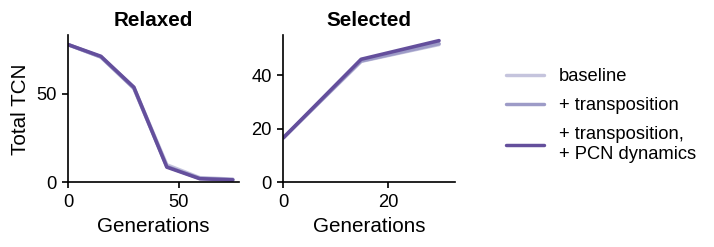

In [3]:
fixed_frames=[]
for config in CONFIGS:
    for phase, duration, init in (
        ("loss", RELAXED_DAYS_PER_CYCLE, fixed_loss_initial_state(MAX_PCN)),
        ("gain", SELECTED_DAYS_PER_CYCLE, fixed_gain_initial_state(MAX_PCN)),
    ):
        traj, daily, _, summary = simulate_phase(
            MAX_PCN, config, phase=phase, duration_days=duration,
            initial_state=init.copy(), record_trajectory=True,
        )
        traj["phase"] = phase
        fixed_frames.append(traj)
fixed = pd.concat(fixed_frames, ignore_index=True)

# Published Figure 2e: separate y ranges, daily-endpoint polylines, legend right.
fig = plt.figure(figsize=(7.25, 2.48))
axes = [fig.add_axes([0.120, 0.27, 0.215, 0.54]),
        fig.add_axes([0.390, 0.27, 0.215, 0.54])]
for ax, phase, title in zip(axes, ("loss", "gain"), ("Relaxed", "Selected")):
    for condition in CONDITION_ORDER:
        d = fixed[(fixed.phase == phase) & (fixed.condition == condition)]
        d = daily_endpoints(d, "phase_day")
        ax.plot(d.phase_day * PASSAGE_GENERATIONS, d.TCN_per_density,
                color=REFERENCE_COLORS[condition], lw=2.35,
                linestyle="-", solid_capstyle="round", solid_joinstyle="round")
    ax.set_title(title, weight="bold", pad=6)
    ax.set_xlabel("Generations")
    ax.set_xlim(0, (RELAXED_DAYS_PER_CYCLE if phase == "loss" else
                    SELECTED_DAYS_PER_CYCLE) * PASSAGE_GENERATIONS + 3)
axes[0].set_ylim(0, 83)
axes[0].set_xticks([0, 50])
axes[0].set_yticks([0, 50])
axes[0].set_ylabel("Total TCN")
axes[1].set_ylim(0, 55)
axes[1].set_xticks([0, 20])
axes[1].set_yticks([0, 20, 40])
fig.legend(handles=reference_legend_handles(), loc="center left",
           bbox_to_anchor=(0.660, 0.515), frameon=False,
           handlelength=2.1, labelspacing=0.66,
           borderaxespad=0, handletextpad=0.8)
save_figure(fig, "Figure2e_fixed_environments", FIGURE_DIR)
plt.show()
export_table(fixed, "Figure2e_source_data.csv", SOURCE_DIR)

## Figure 2f–g: converged fluctuating selection

In [4]:
periodic_frames=[]
summary_rows=[]
for config in CONFIGS:
    conv = converge_periodic_state(MAX_PCN, config, periodic_initial_state(MAX_PCN))
    if not conv["converged"]:
        raise RuntimeError(f"Figure 2 did not converge for {config.condition}")
    traj, post = simulate_post_convergence_cycles(MAX_PCN, config, conv["state"])
    periodic_frames.append(traj)
    metrics = periodic_metrics(
        conv["TCN_low"], conv["TCN_high"], conv["minimum_daily_prepassage_density"],
        converged=conv["converged"], population_extinct=conv["population_extinct"],
    )
    summary_rows.append({
        "condition": config.condition,
        "cycles_to_convergence": conv["cycles_to_convergence"],
        "rate_source": "convergence cycle",
        "TCN_low": conv["TCN_low"],
        "TCN_high": conv["TCN_high"],
        "minimum_daily_prepassage_density": conv["minimum_daily_prepassage_density"],
        **metrics,
    })
periodic = pd.concat(periodic_frames, ignore_index=True)
summary = pd.DataFrame(summary_rows)

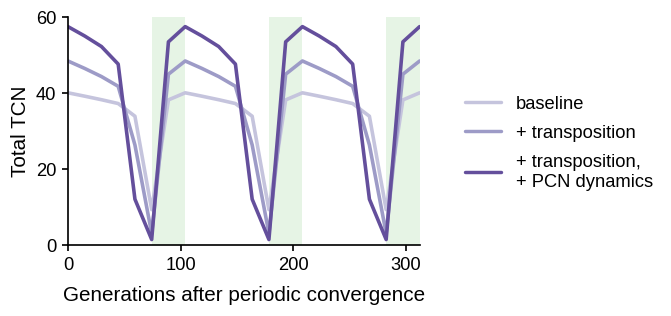

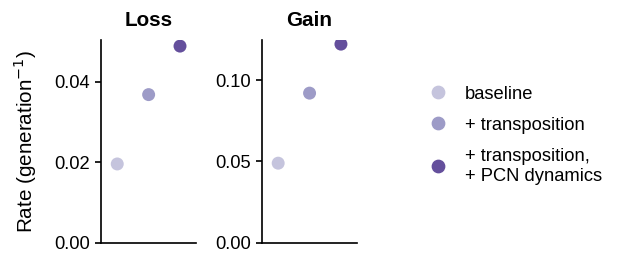

In [5]:
# Published Figure 2f: three post-convergence cycles shown as daily
# passage-endpoint polylines. Green bands mark the selected passages.
fig = plt.figure(figsize=(7.30, 3.05))
ax = fig.add_axes([0.105, 0.25, 0.438, 0.68])
for cycle in range(1, ADDITIONAL_CYCLES_AFTER_CONVERGENCE + 1):
    start = (cycle - 1) * DAYS_PER_CYCLE + RELAXED_DAYS_PER_CYCLE
    ax.axvspan(start * PASSAGE_GENERATIONS,
               (start + SELECTED_DAYS_PER_CYCLE) * PASSAGE_GENERATIONS,
               color=REFERENCE_SHADE, lw=0, zorder=0)
for condition in CONDITION_ORDER:
    d = periodic[periodic.condition == condition]
    d = daily_endpoints(d, "Day")
    ax.plot(d.Day * PASSAGE_GENERATIONS, d.TCN_per_density,
            color=REFERENCE_COLORS[condition], lw=2.35,
            linestyle="-", solid_capstyle="round", solid_joinstyle="round")
ax.set_xlabel("Generations after periodic convergence", labelpad=8)
ax.set_ylabel("Total TCN")
ax.set_ylim(0, 60)
ax.set_yticks([0, 20, 40, 60])
ax.set_xticks([0, 100, 200, 300])
ax.set_xlim(0, ADDITIONAL_CYCLES_AFTER_CONVERGENCE *
              DAYS_PER_CYCLE * PASSAGE_GENERATIONS)
fig.legend(handles=reference_legend_handles(), loc="center left",
           bbox_to_anchor=(0.590, 0.555), frameon=False,
           handlelength=2.0, labelspacing=0.65,
           borderaxespad=0, handletextpad=0.8)
save_figure(fig, "Figure2f_fluctuating", FIGURE_DIR)
plt.show()

# Published Figure 2g: independent loss/gain axes with three offset circles;
# no bars or category names on the x axis (legend identifies the circles).
fig = plt.figure(figsize=(6.65, 3.10))
axes = [fig.add_axes([0.185, 0.235, 0.130, 0.595]),
        fig.add_axes([0.405, 0.235, 0.130, 0.595])]
for ax, metric, title, ymax, ticks in zip(
    axes, ("loss_rate", "gain_rate"), ("Loss", "Gain"),
    (0.0505, 0.125), ([0, 0.02, 0.04], [0, 0.05, 0.10])
):
    vals = [summary.loc[summary.condition == c, metric].iloc[0]
            for c in CONDITION_ORDER]
    for x, c, v in zip((0.17, 0.50, 0.83), CONDITION_ORDER, vals):
        ax.scatter([x], [v], s=72, facecolors=REFERENCE_COLORS[c],
                   edgecolors="none", zorder=3)
    ax.set_title(title, weight="bold", pad=9)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, ymax)
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:.2f}" for t in ticks])
    ax.set_xticks([])
axes[0].set_ylabel("Rate (generation$^{-1}$)", labelpad=10)
fig.legend(handles=reference_legend_handles(kind="scatter"),
           loc="center left", bbox_to_anchor=(0.610, 0.55),
           frameon=False, handletextpad=0.5, borderaxespad=0,
           labelspacing=0.78, markerscale=1.0)
save_figure(fig, "Figure2g_response_rates", FIGURE_DIR)
plt.show()

export_table(periodic, "Figure2f_source_data.csv", SOURCE_DIR)
export_table(summary, "Figure2g_source_data.csv", SOURCE_DIR)
export_table(core_metadata("Figure 2"), "Figure2_run_metadata.csv", SOURCE_DIR)